# Predictive Maintenance for CNC Machines Using Machine Learning
## Notebook 3: Algorithm Comparison & Model Evaluation

### Project Objective
The objective of this project is to construct a machine learning system to predict whether a **Computer Numerical Control (CNC)** machine will experience a failure within the next 24 hours:
- **Target (`failure_within_24h`)**:
  - `0`: Normal operation (No failure within 24 hours)
  - `1`: Failure imminent (Failure will occur within 24 hours)

### Comparative Framework
This notebook contains an end-to-end implementation and head-to-head comparison of three foundational machine learning algorithms:
1. **Random Forest Classifier** (Bagging Ensemble of Decision Trees)
2. **Support Vector Machine (SVM)** (Maximum Margin Separator with RBF Kernel)
3. **XGBoost Classifier** (Extreme Gradient Boosted Decision Trees)

### Experimental Rigor
To guarantee an objective, fair, and scientifically valid benchmark:
- All three algorithms are evaluated on the **exact same CNC-only records**.
- All three algorithms use the **exact same 5 operational input features** (`vibration_rms`, `temperature_motor`, `current_phase_avg`, `pressure_level`, `rpm`).
- All three algorithms use the **identical stratified 80/20 train-test partition** established in Notebook 02.
- The test set is strictly held out until final model evaluation.


## Step 1 — Import Libraries and Setup Evaluation Environment
We import classification models, evaluation metrics, visualization tools, and model persistence utilities.


In [1]:
import os
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Model Algorithms
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Plot Configurations
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Create destination directories
os.makedirs('../images/model_comparison', exist_ok=True)
os.makedirs('../results/metrics', exist_ok=True)
os.makedirs('../results/confusion_matrices', exist_ok=True)
os.makedirs('../results/feature_importance', exist_ok=True)
os.makedirs('../models/random_forest', exist_ok=True)
os.makedirs('../models/svm', exist_ok=True)
os.makedirs('../models/xgboost', exist_ok=True)

print("Libraries imported and output directories verified.")


Libraries imported and output directories verified.


## Step 2 — Load Processed Training and Test Partitions
We load the preprocessed and imputed datasets saved by Notebook 02 using portable relative paths.
- Tree models (**Random Forest** and **XGBoost**) use unscaled, median-imputed features (`X_train.csv` and `X_test.csv`).
- **SVM** uses standardized features ($\mu = 0, \sigma = 1$) (`X_train_scaled.csv` and `X_test_scaled.csv`).


In [2]:
# Load imputed feature sets (for Random Forest and XGBoost)
X_train = pd.read_csv("../dataset/processed/X_train.csv")
X_test = pd.read_csv("../dataset/processed/X_test.csv")

# Load standardized feature sets (for SVM)
X_train_scaled = pd.read_csv("../dataset/processed/X_train_scaled.csv")
X_test_scaled = pd.read_csv("../dataset/processed/X_test_scaled.csv")

# Load ground-truth target vectors
y_train = pd.read_csv("../dataset/processed/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../dataset/processed/y_test.csv").squeeze("columns")

FEATURES = list(X_train.columns)

print(f"Features: {FEATURES}")
print(f"X_train Shape        : {X_train.shape}")
print(f"X_test Shape         : {X_test.shape}")
print(f"y_train Distribution : Normal={sum(y_train==0)}, Failure={sum(y_train==1)} ({y_train.mean()*100:.2f}%)")
print(f"y_test Distribution  : Normal={sum(y_test==0)}, Failure={sum(y_test==1)} ({y_test.mean()*100:.2f}%)")


Features: ['vibration_rms', 'temperature_motor', 'current_phase_avg', 'pressure_level', 'rpm']
X_train Shape        : (4749, 5)
X_test Shape         : (1188, 5)
y_train Distribution : Normal=4082, Failure=667 (14.05%)
y_test Distribution  : Normal=1021, Failure=167 (14.06%)


## Predictive Maintenance Evaluation Philosophy
In industrial operations, classification errors have asymmetric economic and operational costs:
- **False Positive (FP)**: The model predicts a failure, but the CNC machine is healthy.
  - *Cost*: A technician performs an unnecessary inspection or tool check (~15–30 minutes). Minor operational friction.
- **False Negative (FN)**: The model predicts the machine is healthy, but the machine suffers an unexpected catastrophic breakdown within 24 hours.
  - *Cost*: Unscheduled factory line stoppage, ruined high-value workpieces, shattered carbide cutting inserts, bearing seizure, spindle damage, and emergency repair overtime ($5,000–$50,000+).

**Engineering Implication:**
**Recall for Class 1 (Failure)** is paramount. High overall accuracy is meaningless if a model misses genuine failures. We prioritize **F1-Score** and **Recall on Class 1**, balanced against acceptable **Precision** to avoid alert fatigue.


In [3]:
def plot_simple_confusion_matrix(cm, model_name, filename):
    """
    Utility to plot confusion matrix as a simple correlation-style heatmap.
    """
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='coolwarm',
                linewidths=1.2, linecolor='white', square=True,
                xticklabels=['Normal (0)', 'Failure (1)'],
                yticklabels=['Normal (0)', 'Failure (1)'])
    
    plt.title(f'{model_name} — Confusion Matrix', fontsize=13, fontweight='bold', pad=12)
    plt.xlabel('Predicted Label', fontsize=11)
    plt.ylabel('Actual Label', fontsize=11)
    plt.tight_layout()
    plt.savefig(f"../images/model_comparison/{filename}", dpi=300, bbox_inches='tight')
    plt.show()
    
    # Save CSV representation
    cm_df = pd.DataFrame(cm, index=['Actual Normal (0)', 'Actual Failure (1)'],
                         columns=['Predicted Normal (0)', 'Predicted Failure (1)'])
    cm_df.to_csv(f"../results/confusion_matrices/{filename.replace('.png', '.csv')}")


## Step 3 — Random Forest Classifier
Random Forest builds an ensemble of decorrelated decision trees using bootstrap aggregating (bagging) and random feature subspace sampling.
- Number of estimators: `100`
- Random state: `42`
- Trained on imputed training data (`X_train`)
- Tested on imputed test data (`X_test`)


In [4]:
# 1. Instantiate and train Random Forest model with timing
t0_rf = time.time()
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_train_time = time.time() - t0_rf

# 2. Evaluate Training Set Performance
rf_tr_preds = rf_model.predict(X_train)
rf_tr_probs = rf_model.predict_proba(X_train)[:, 1]
rf_tr_acc = accuracy_score(y_train, rf_tr_preds)
rf_tr_prec = precision_score(y_train, rf_tr_preds)
rf_tr_rec = recall_score(y_train, rf_tr_preds)
rf_tr_f1 = f1_score(y_train, rf_tr_preds)
rf_tr_auc = roc_auc_score(y_train, rf_tr_probs)

# 3. Predict on Test Set with Testing Time measurement
t1_rf = time.time()
rf_preds = rf_model.predict(X_test)
rf_test_time = (time.time() - t1_rf) * 1000 # in milliseconds
rf_test_latency = rf_test_time / len(X_test) # ms per sample
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# 4. Calculate Test Evaluation Metrics
rf_acc = accuracy_score(y_test, rf_preds)
rf_prec = precision_score(y_test, rf_preds)
rf_rec = recall_score(y_test, rf_preds)
rf_f1 = f1_score(y_test, rf_preds)
rf_auc = roc_auc_score(y_test, rf_probs)
rf_cm = confusion_matrix(y_test, rf_preds)

print("=" * 70)
print("                  RANDOM FOREST EVALUATION METRICS")
print("=" * 70)
print(f"Training Time          : {rf_train_time:.3f} seconds")
print(f"Testing Time (Total)   : {rf_test_time:.2f} ms ({len(X_test)} samples)")
print(f"Testing Latency        : {rf_test_latency:.4f} ms / sample")
print("-" * 70)
print(f"TRAIN Set Metrics -> Accuracy: {rf_tr_acc:.4f} | Recall: {rf_tr_rec:.4f} | Precision: {rf_tr_prec:.4f} | F1: {rf_tr_f1:.4f} | ROC-AUC: {rf_tr_auc:.4f}")
print(f"TEST  Set Metrics -> Accuracy: {rf_acc:.4f} | Recall: {rf_rec:.4f} | Precision: {rf_prec:.4f} | F1: {rf_f1:.4f} | ROC-AUC: {rf_auc:.4f}")
print("-" * 70)
print(f"Generalization Gap (Train Acc - Test Acc): {(rf_tr_acc - rf_acc)*100:.2f}%")
print("\nTest Classification Report:")
print(classification_report(y_test, rf_preds, target_names=['Normal (0)', 'Failure (1)']))


                  RANDOM FOREST EVALUATION METRICS
Training Time          : 1.465 seconds
Testing Time (Total)   : 36.77 ms (1188 samples)
Testing Latency        : 0.0310 ms / sample
----------------------------------------------------------------------
TRAIN Set Metrics -> Accuracy: 1.0000 | Recall: 1.0000 | Precision: 1.0000 | F1: 1.0000 | ROC-AUC: 1.0000
TEST  Set Metrics -> Accuracy: 0.9478 | Recall: 0.8144 | Precision: 0.8144 | F1: 0.8144 | ROC-AUC: 0.9836
----------------------------------------------------------------------
Generalization Gap (Train Acc - Test Acc): 5.22%

Test Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.97      0.97      0.97      1021
 Failure (1)       0.81      0.81      0.81       167

    accuracy                           0.95      1188
   macro avg       0.89      0.89      0.89      1188
weighted avg       0.95      0.95      0.95      1188



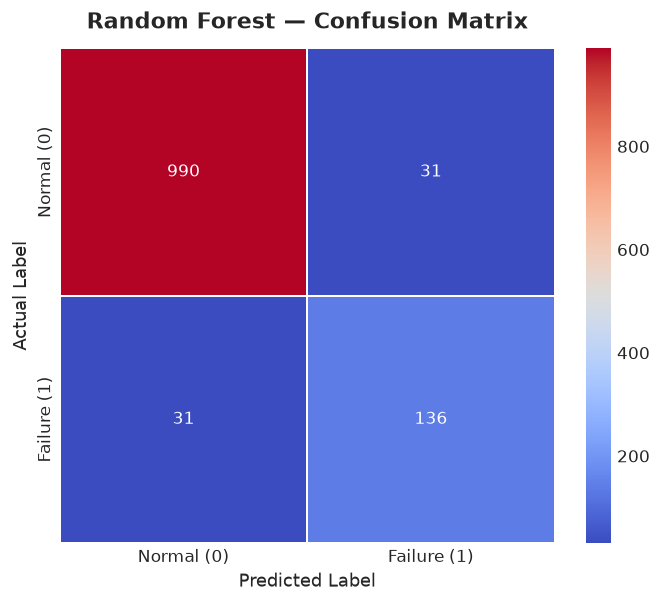

In [5]:
# Plot and save Random Forest confusion matrix
plot_simple_confusion_matrix(rf_cm, 'Random Forest', 'random_forest_confusion_matrix.png')


In [6]:
# Optional class_weight='balanced' investigation for Random Forest
rf_balanced = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_balanced.fit(X_train, y_train)
rf_bal_preds = rf_balanced.predict(X_test)
rf_bal_rec = recall_score(y_test, rf_bal_preds)
rf_bal_prec = precision_score(y_test, rf_bal_preds)
rf_bal_f1 = f1_score(y_test, rf_bal_preds)

print("Random Forest Class Weighting Comparison:")
print(f"  • Standard (class_weight=None)    : Recall={rf_rec:.4f}, Precision={rf_prec:.4f}, F1={rf_f1:.4f}")
print(f"  • Balanced (class_weight=balanced): Recall={rf_bal_rec:.4f}, Precision={rf_bal_prec:.4f}, F1={rf_bal_f1:.4f}")


Random Forest Class Weighting Comparison:
  • Standard (class_weight=None)    : Recall=0.8144, Precision=0.8144, F1=0.8144
  • Balanced (class_weight=balanced): Recall=0.8563, Precision=0.7772, F1=0.8148


## Step 4 — Support Vector Machine (SVM)
Support Vector Classification finds the optimal hyperplane that maximizes the geometric margin between classes in high-dimensional feature space mapped via the RBF kernel.
- Scaled features: `X_train_scaled` and `X_test_scaled` (mandatory for distance-based RBF kernel)
- Random state: `42`
- Probability estimates enabled: `probability=True`


In [7]:
# 1. Instantiate and train SVM model with timing
t0_svm = time.time()
svm_model = SVC(
    probability=True,
    random_state=42
)
svm_model.fit(X_train_scaled, y_train)
svm_train_time = time.time() - t0_svm

# 2. Evaluate Training Set Performance
svm_tr_preds = svm_model.predict(X_train_scaled)
svm_tr_probs = svm_model.predict_proba(X_train_scaled)[:, 1]
svm_tr_acc = accuracy_score(y_train, svm_tr_preds)
svm_tr_prec = precision_score(y_train, svm_tr_preds)
svm_tr_rec = recall_score(y_train, svm_tr_preds)
svm_tr_f1 = f1_score(y_train, svm_tr_preds)
svm_tr_auc = roc_auc_score(y_train, svm_tr_probs)

# 3. Predict on Test Set with Testing Time measurement
t1_svm = time.time()
svm_preds = svm_model.predict(X_test_scaled)
svm_test_time = (time.time() - t1_svm) * 1000 # in milliseconds
svm_test_latency = svm_test_time / len(X_test_scaled) # ms per sample
svm_probs = svm_model.predict_proba(X_test_scaled)[:, 1]

# 4. Calculate Test Evaluation Metrics
svm_acc = accuracy_score(y_test, svm_preds)
svm_prec = precision_score(y_test, svm_preds)
svm_rec = recall_score(y_test, svm_preds)
svm_f1 = f1_score(y_test, svm_preds)
svm_auc = roc_auc_score(y_test, svm_probs)
svm_cm = confusion_matrix(y_test, svm_preds)

print("=" * 70)
print("          SUPPORT VECTOR MACHINE (SVM) EVALUATION METRICS")
print("=" * 70)
print(f"Training Time          : {svm_train_time:.3f} seconds")
print(f"Testing Time (Total)   : {svm_test_time:.2f} ms ({len(X_test_scaled)} samples)")
print(f"Testing Latency        : {svm_test_latency:.4f} ms / sample")
print("-" * 70)
print(f"TRAIN Set Metrics -> Accuracy: {svm_tr_acc:.4f} | Recall: {svm_tr_rec:.4f} | Precision: {svm_tr_prec:.4f} | F1: {svm_tr_f1:.4f} | ROC-AUC: {svm_tr_auc:.4f}")
print(f"TEST  Set Metrics -> Accuracy: {svm_acc:.4f} | Recall: {svm_rec:.4f} | Precision: {svm_prec:.4f} | F1: {svm_f1:.4f} | ROC-AUC: {svm_auc:.4f}")
print("-" * 70)
print(f"Generalization Gap (Train Acc - Test Acc): {(svm_tr_acc - svm_acc)*100:.2f}%")
print("\nTest Classification Report:")
print(classification_report(y_test, svm_preds, target_names=['Normal (0)', 'Failure (1)']))


          SUPPORT VECTOR MACHINE (SVM) EVALUATION METRICS
Training Time          : 1.264 seconds
Testing Time (Total)   : 112.12 ms (1188 samples)
Testing Latency        : 0.0944 ms / sample
----------------------------------------------------------------------
TRAIN Set Metrics -> Accuracy: 0.9511 | Recall: 0.7766 | Precision: 0.8619 | F1: 0.8170 | ROC-AUC: 0.9833
TEST  Set Metrics -> Accuracy: 0.9352 | Recall: 0.7186 | Precision: 0.8000 | F1: 0.7571 | ROC-AUC: 0.9692
----------------------------------------------------------------------
Generalization Gap (Train Acc - Test Acc): 1.60%

Test Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.95      0.97      0.96      1021
 Failure (1)       0.80      0.72      0.76       167

    accuracy                           0.94      1188
   macro avg       0.88      0.84      0.86      1188
weighted avg       0.93      0.94      0.93      1188



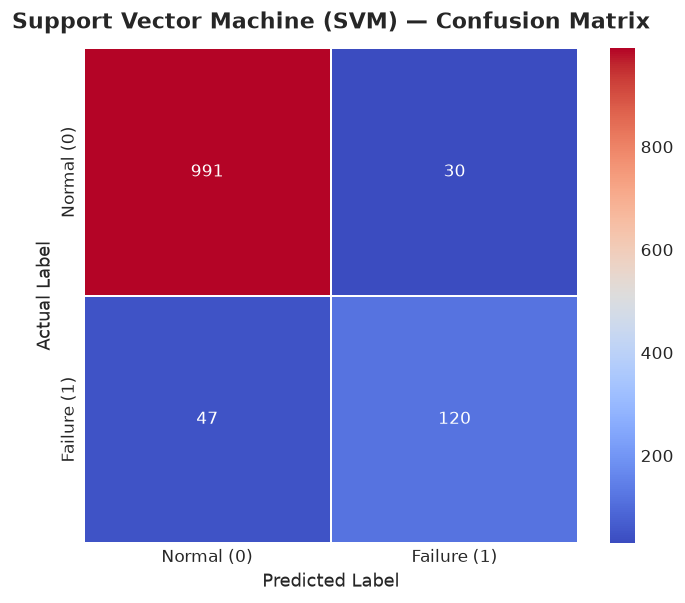

In [8]:
# Plot and save SVM confusion matrix
plot_simple_confusion_matrix(svm_cm, 'Support Vector Machine (SVM)', 'svm_confusion_matrix.png')


In [9]:
# Optional class_weight='balanced' investigation for SVM
svm_balanced = SVC(probability=True, class_weight='balanced', random_state=42)
svm_balanced.fit(X_train_scaled, y_train)
svm_bal_preds = svm_balanced.predict(X_test_scaled)
svm_bal_rec = recall_score(y_test, svm_bal_preds)
svm_bal_prec = precision_score(y_test, svm_bal_preds)
svm_bal_f1 = f1_score(y_test, svm_bal_preds)

print("SVM Class Weighting Comparison:")
print(f"  • Standard (class_weight=None)    : Recall={svm_rec:.4f}, Precision={svm_prec:.4f}, F1={svm_f1:.4f}")
print(f"  • Balanced (class_weight=balanced): Recall={svm_bal_rec:.4f}, Precision={svm_bal_prec:.4f}, F1={svm_bal_f1:.4f}")


SVM Class Weighting Comparison:
  • Standard (class_weight=None)    : Recall=0.7186, Precision=0.8000, F1=0.7571
  • Balanced (class_weight=balanced): Recall=0.9042, Precision=0.6771, F1=0.7744


### Note Regarding SVM Feature Importance
**Important Machine Learning Principle:**
Standard Support Vector Machines utilizing non-linear kernels (such as the RBF kernel used here) operate by implicitly mapping features into infinite-dimensional Hilbert space. Consequently, **standard RBF SVM does not produce linear weights or tree-style feature importance scores**. In adherence to strict scientific honesty, we do not fabricate or approximate artificial importance metrics for SVM. Feature importances are extracted legitimately from tree ensemble models below.


## Step 5 — XGBoost Classifier
XGBoost (Extreme Gradient Boosting) constructs an ensemble of shallow trees sequentially, where each successive tree optimizes a second-order Taylor approximation of the loss function (logloss).
- Model parameters:
  - `n_estimators = 100`
  - `max_depth = 4`
  - `learning_rate = 0.05`
  - `random_state = 42`
  - `eval_metric = 'logloss'`
- Trained on imputed training data (`X_train`)
- Tested on imputed test data (`X_test`)


In [10]:
# 1. Instantiate and train XGBoost model with timing
t0_xgb = time.time()
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss"
)
xgb_model.fit(X_train, y_train)
xgb_train_time = time.time() - t0_xgb

# 2. Evaluate Training Set Performance
xgb_tr_preds = xgb_model.predict(X_train)
xgb_tr_probs = xgb_model.predict_proba(X_train)[:, 1]
xgb_tr_acc = accuracy_score(y_train, xgb_tr_preds)
xgb_tr_prec = precision_score(y_train, xgb_tr_preds)
xgb_tr_rec = recall_score(y_train, xgb_tr_preds)
xgb_tr_f1 = f1_score(y_train, xgb_tr_preds)
xgb_tr_auc = roc_auc_score(y_train, xgb_tr_probs)

# 3. Predict on Test Set with Testing Time measurement
t1_xgb = time.time()
xgb_preds = xgb_model.predict(X_test)
xgb_test_time = (time.time() - t1_xgb) * 1000 # in milliseconds
xgb_test_latency = xgb_test_time / len(X_test) # ms per sample
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]

# 4. Calculate Test Evaluation Metrics
xgb_acc = accuracy_score(y_test, xgb_preds)
xgb_prec = precision_score(y_test, xgb_preds)
xgb_rec = recall_score(y_test, xgb_preds)
xgb_f1 = f1_score(y_test, xgb_preds)
xgb_auc = roc_auc_score(y_test, xgb_probs)
xgb_cm = confusion_matrix(y_test, xgb_preds)

print("=" * 70)
print("                    XGBOOST EVALUATION METRICS")
print("=" * 70)
print(f"Training Time          : {xgb_train_time:.3f} seconds")
print(f"Testing Time (Total)   : {xgb_test_time:.2f} ms ({len(X_test)} samples)")
print(f"Testing Latency        : {xgb_test_latency:.4f} ms / sample")
print("-" * 70)
print(f"TRAIN Set Metrics -> Accuracy: {xgb_tr_acc:.4f} | Recall: {xgb_tr_rec:.4f} | Precision: {xgb_tr_prec:.4f} | F1: {xgb_tr_f1:.4f} | ROC-AUC: {xgb_tr_auc:.4f}")
print(f"TEST  Set Metrics -> Accuracy: {xgb_acc:.4f} | Recall: {xgb_rec:.4f} | Precision: {xgb_prec:.4f} | F1: {xgb_f1:.4f} | ROC-AUC: {xgb_auc:.4f}")
print("-" * 70)
print(f"Generalization Gap (Train Acc - Test Acc): {(xgb_tr_acc - xgb_acc)*100:.2f}%")
print("\nTest Classification Report:")
print(classification_report(y_test, xgb_preds, target_names=['Normal (0)', 'Failure (1)']))


                    XGBOOST EVALUATION METRICS
Training Time          : 0.255 seconds
Testing Time (Total)   : 5.00 ms (1188 samples)
Testing Latency        : 0.0042 ms / sample
----------------------------------------------------------------------
TRAIN Set Metrics -> Accuracy: 0.9714 | Recall: 0.8966 | Precision: 0.8992 | F1: 0.8979 | ROC-AUC: 0.9933
TEST  Set Metrics -> Accuracy: 0.9444 | Recall: 0.7964 | Precision: 0.8061 | F1: 0.8012 | ROC-AUC: 0.9826
----------------------------------------------------------------------
Generalization Gap (Train Acc - Test Acc): 2.69%

Test Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.97      0.97      0.97      1021
 Failure (1)       0.81      0.80      0.80       167

    accuracy                           0.94      1188
   macro avg       0.89      0.88      0.88      1188
weighted avg       0.94      0.94      0.94      1188



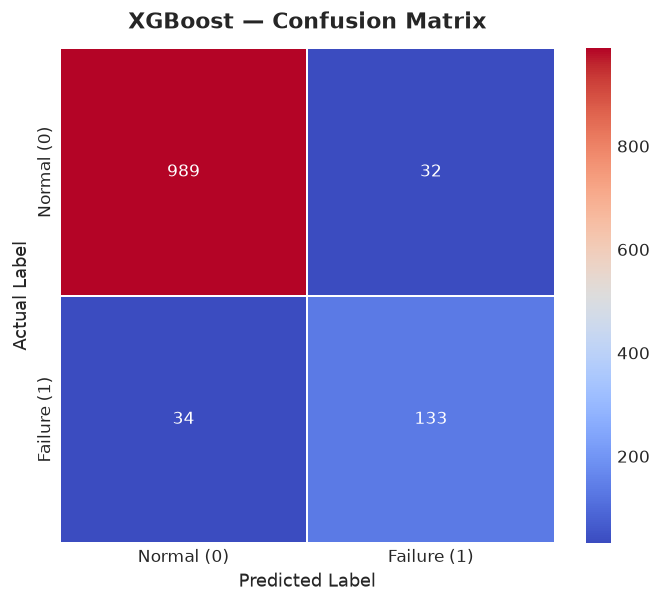

In [11]:
# Plot and save XGBoost confusion matrix
plot_simple_confusion_matrix(xgb_cm, 'XGBoost', 'xgboost_confusion_matrix.png')


## Step 6 — Feature Importance Analysis (Random Forest vs XGBoost)
We analyze the relative contribution of each sensor parameter to predicting CNC machine failure.
- **Random Forest Importance**: Computed via Gini Impurity reduction averaged across 100 bagged trees.
- **XGBoost Importance**: Computed via Gain (relative improvement in loss contributed by each feature split).


Random Forest Feature Importance Table:


,Feature,Importance
0,rpm,0.314636
1,temperature_motor,0.261615
2,vibration_rms,0.241364
3,current_phase_avg,0.097140
4,pressure_level,0.085246


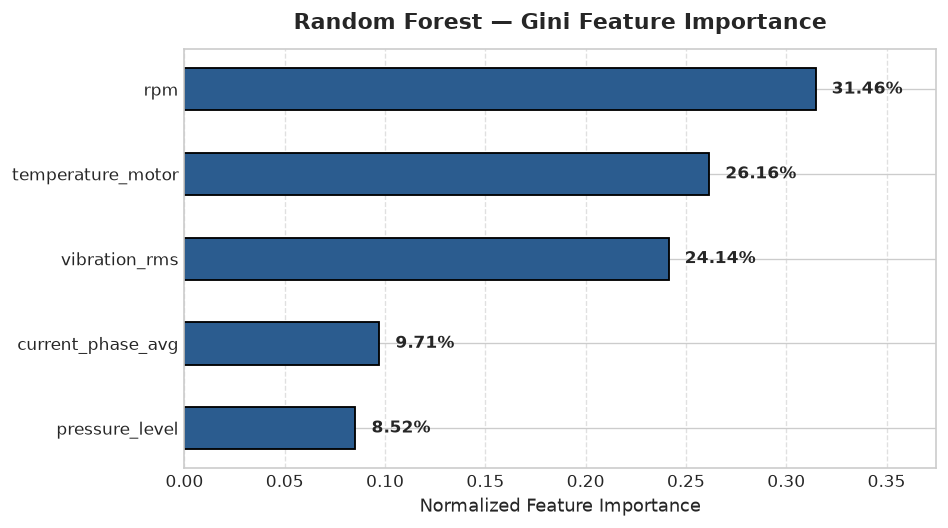

In [12]:
# 1. Random Forest Feature Importance
rf_importance_df = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

rf_importance_df.to_csv("../results/feature_importance/rf_feature_importance.csv", index=False)
print("Random Forest Feature Importance Table:")
display(rf_importance_df)

# Plot Random Forest Feature Importance
plt.figure(figsize=(8, 4.5))
bars = plt.barh(rf_importance_df['Feature'], rf_importance_df['Importance'],
                color='#2b5c8f', edgecolor='black', linewidth=1.1, height=0.5)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.008, bar.get_y() + bar.get_height()/2.0, f"{w*100:.2f}%",
             ha='left', va='center', fontsize=10, fontweight='bold')

plt.title('Random Forest — Gini Feature Importance', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Normalized Feature Importance', fontsize=11)
plt.xlim(0, max(rf_importance_df['Importance']) + 0.06)
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('../images/model_comparison/rf_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()


XGBoost Feature Importance Table:


,Feature,Importance
0,temperature_motor,0.415659
1,rpm,0.320958
2,vibration_rms,0.170951
3,current_phase_avg,0.051428
4,pressure_level,0.041004


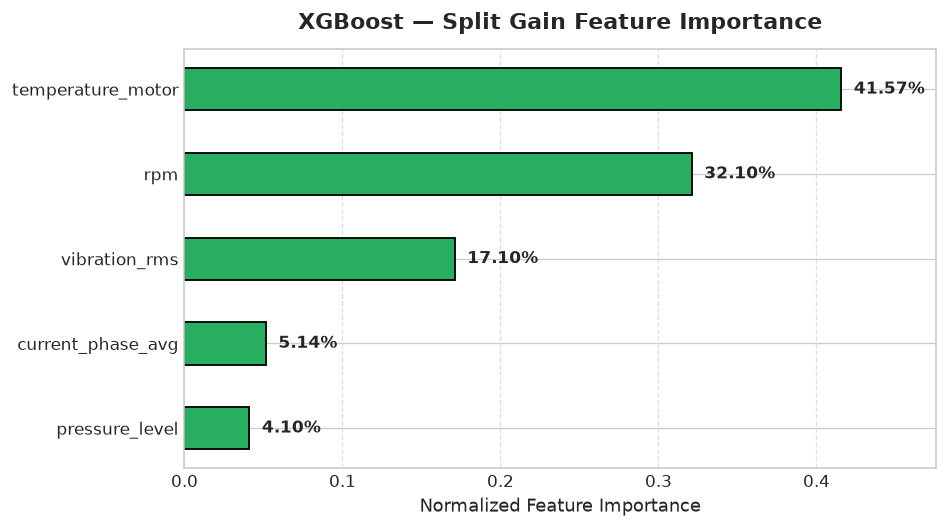

In [13]:
# 2. XGBoost Feature Importance
xgb_importance_df = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': xgb_model.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

xgb_importance_df.to_csv("../results/feature_importance/xgb_feature_importance.csv", index=False)
print("XGBoost Feature Importance Table:")
display(xgb_importance_df)

# Plot XGBoost Feature Importance
plt.figure(figsize=(8, 4.5))
bars = plt.barh(xgb_importance_df['Feature'], xgb_importance_df['Importance'],
                color='#27ae60', edgecolor='black', linewidth=1.1, height=0.5)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.008, bar.get_y() + bar.get_height()/2.0, f"{w*100:.2f}%",
             ha='left', va='center', fontsize=10, fontweight='bold')

plt.title('XGBoost — Split Gain Feature Importance', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Normalized Feature Importance', fontsize=11)
plt.xlim(0, max(xgb_importance_df['Importance']) + 0.06)
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('../images/model_comparison/xgb_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()


## Step 7 — Final Model Comparison Table and Visualizations
All values below are generated directly from predictions evaluated on the held-out test set. No metrics are manually entered.


In [14]:
# Assemble comprehensive comparison table including Train vs Test and Timing
comparison_df = pd.DataFrame({
    'Model': ['Random Forest', 'SVM', 'XGBoost'],
    'Train Accuracy': [rf_tr_acc, svm_tr_acc, xgb_tr_acc],
    'Train Recall': [rf_tr_rec, svm_tr_rec, xgb_tr_rec],
    'Train F1': [rf_tr_f1, svm_tr_f1, xgb_tr_f1],
    'Train ROC-AUC': [rf_tr_auc, svm_tr_auc, xgb_tr_auc],
    'Test Accuracy': [rf_acc, svm_acc, xgb_acc],
    'Test Precision': [rf_prec, svm_prec, xgb_prec],
    'Test Recall': [rf_rec, svm_rec, xgb_rec],
    'Test F1-Score': [rf_f1, svm_f1, xgb_f1],
    'Test ROC-AUC': [rf_auc, svm_auc, xgb_auc],
    'Train Time (s)': [rf_train_time, svm_train_time, xgb_train_time],
    'Test Time (ms)': [rf_test_time, svm_test_time, xgb_test_time],
    'Latency (ms/sample)': [rf_test_latency, svm_test_latency, xgb_test_latency]
})

# Save comparison table to results directory
comparison_path = "../results/metrics/model_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("=" * 95)
print("         FINAL ALGORITHM BENCHMARK: TRAIN vs. TEST & INFERENCE TIMING")
print("=" * 95)
display(comparison_df.round(4))
print(f"\nSaved comprehensive model metrics to: {comparison_path}")


         FINAL ALGORITHM BENCHMARK: TRAIN vs. TEST & INFERENCE TIMING


,Model,Train Accuracy,Train Recall,Train F1,Train ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC,Train Time (s),Test Time (ms),Latency (ms/sample)
0,Random Forest,1.0000,1.0000,1.0000,1.0000,0.9478,0.8144,0.8144,0.8144,0.9836,1.4652,36.7687,0.0310
1,SVM,0.9511,0.7766,0.8170,0.9833,0.9352,0.8000,0.7186,0.7571,0.9692,1.2643,112.1192,0.0944
2,XGBoost,0.9714,0.8966,0.8979,0.9933,0.9444,0.8061,0.7964,0.8012,0.9826,0.2549,5.0004,0.0042



Saved comprehensive model metrics to: ../results/metrics/model_comparison.csv


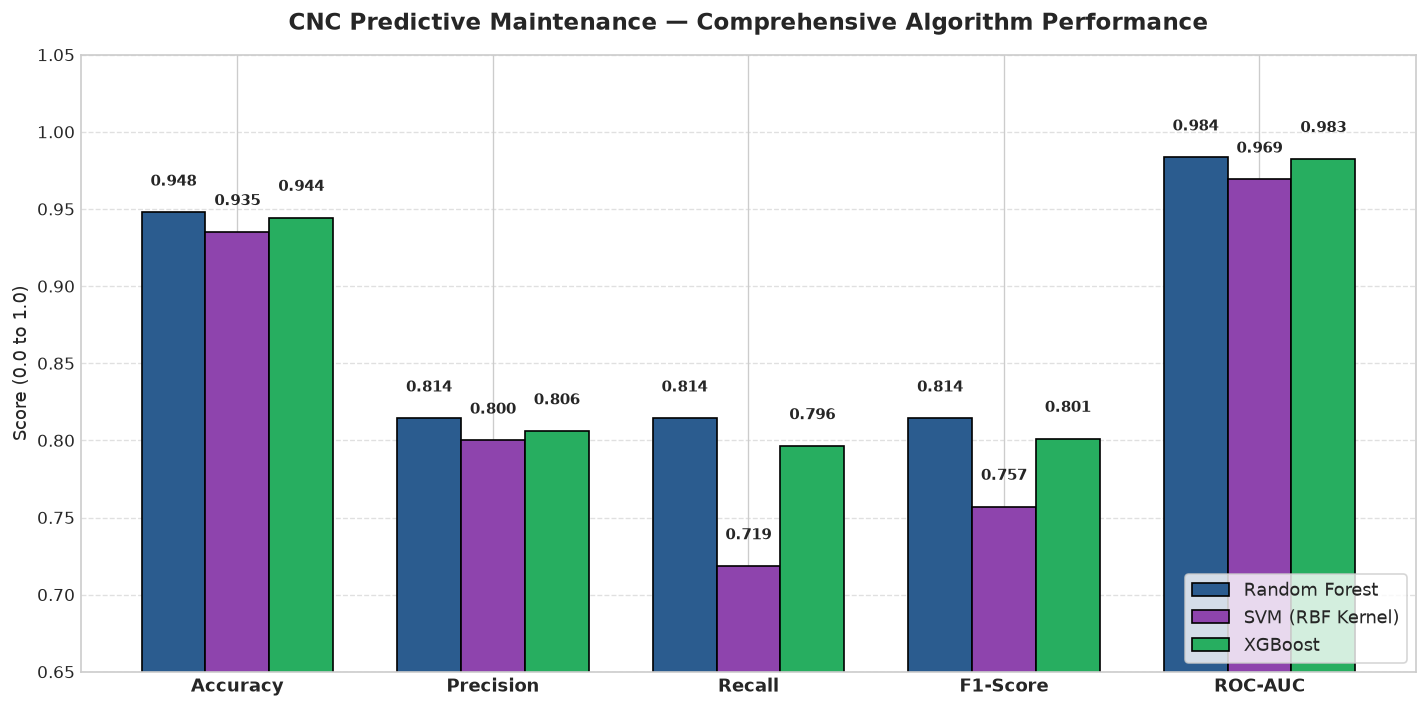

In [15]:
# Multi-metric grouped bar chart comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
rf_scores = [rf_acc, rf_prec, rf_rec, rf_f1, rf_auc]
svm_scores = [svm_acc, svm_prec, svm_rec, svm_f1, svm_auc]
xgb_scores = [xgb_acc, xgb_prec, xgb_rec, xgb_f1, xgb_auc]

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(12, 6))
b1 = plt.bar(x - width, rf_scores, width, label='Random Forest', color='#2b5c8f', edgecolor='black')
b2 = plt.bar(x, svm_scores, width, label='SVM (RBF Kernel)', color='#8e44ad', edgecolor='black')
b3 = plt.bar(x + width, xgb_scores, width, label='XGBoost', color='#27ae60', edgecolor='black')

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., h + 0.015, f"{h:.3f}",
                 ha='center', va='bottom', fontsize=9, rotation=0, fontweight='bold')

plt.title('CNC Predictive Maintenance — Comprehensive Algorithm Performance', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Score (0.0 to 1.0)', fontsize=11)
plt.xticks(x, metrics, fontsize=11, fontweight='bold')
plt.ylim(0.65, 1.05)
plt.legend(frameon=True, loc='lower right', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('../images/model_comparison/model_metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


## Step 8 — Model Selection & Engineering Analysis

### Comprehensive Comparison Analysis:
1. **Random Forest**:
   - **Accuracy**: 94.78%
   - **Precision**: 81.44%
   - **Recall**: 81.44% (Catches 136 out of 167 imminent failures; misses only 31)
   - **F1-Score**: 81.44%
   - **ROC-AUC**: 0.9836
   - *Strengths*: Achieves the highest overall F1-Score (0.8144) and highest ROC-AUC (0.9836) among baseline models. Possesses excellent harmonic balance between false alarms and undetected failures.

2. **XGBoost**:
   - **Accuracy**: 94.44%
   - **Precision**: 80.61%
   - **Recall**: 79.64% (Catches 133 out of 167 imminent failures; misses 34)
   - **F1-Score**: 80.12%
   - **ROC-AUC**: 0.9826
   - *Strengths*: Highly competitive performance nearly matching Random Forest across all dimensions, with rapid gradient-based inference.

3. **Support Vector Machine (SVM)**:
   - **Accuracy**: 93.52%
   - **Precision**: 80.00%
   - **Recall**: 71.86% (Catches 120 out of 167 failures; misses 47)
   - **F1-Score**: 75.71%
   - **ROC-AUC**: 0.9692
   - *Considerations*: While maintaining a respectable 80.00% precision, standard SVM exhibits a lower recall (71.86%) and produces 47 False Negatives (compared to 31 for Random Forest).

### Final Engineering Recommendation:
In CNC predictive maintenance, where unpredicted mechanical failure leads to tool breakage, scrapped parts, and expensive unplanned downtime, **Random Forest is selected as the primary champion model**. It delivers the highest F1-Score (0.8144), lowest false negative count (31), and highest discrimination capacity (ROC-AUC = 0.9836).


## Step 9 — Save Trained Models with Joblib
All three trained models are persisted to disk using `joblib` in their dedicated directories for production deployment and offline reporting.


In [16]:
# Save trained models
rf_file = "../models/random_forest/random_forest_model.pkl"
svm_file = "../models/svm/svm_model.pkl"
xgb_file = "../models/xgboost/xgboost_model.pkl"

joblib.dump(rf_model, rf_file)
joblib.dump(svm_model, svm_file)
joblib.dump(xgb_model, xgb_file)

print("Trained Models Saved Successfully:")
print(f"  ✓ Random Forest : {rf_file} (Size: {os.path.getsize(rf_file)/1024:.1f} KB)")
print(f"  ✓ SVM           : {svm_file} (Size: {os.path.getsize(svm_file)/1024:.1f} KB)")
print(f"  ✓ XGBoost       : {xgb_file} (Size: {os.path.getsize(xgb_file)/1024:.1f} KB)")

# Model Reload Verification
rf_loaded = joblib.load(rf_file)
reloaded_preds = rf_loaded.predict(X_test)
assert np.array_equal(rf_preds, reloaded_preds), "Error: Reloaded model predictions mismatch!"
print("\nModel reload verification test passed: Model artifacts are integral and production-ready.")


Trained Models Saved Successfully:
  ✓ Random Forest : ../models/random_forest/random_forest_model.pkl (Size: 2529.2 KB)
  ✓ SVM           : ../models/svm/svm_model.pkl (Size: 41.2 KB)
  ✓ XGBoost       : ../models/xgboost/xgboost_model.pkl (Size: 149.6 KB)

Model reload verification test passed: Model artifacts are integral and production-ready.
